# 04 - Installments EDA

Exploratory analysis of `installments_payments.csv`: scheduled and actual installment payments on previous Home Credit loans, linked by `SK_ID_CURR` and `SK_ID_PREV`.

## Purpose

This notebook answers installment-payment questions before feature engineering. It checks table grain and joins, missing payment fields, payment timing (late vs early), over/under-payment amounts, installment calendar versions, and implications for aggregating to previous applications and clients.

**Context:** [00_dataset_overview.ipynb](00_dataset_overview.ipynb) | [01_application_eda.ipynb](01_application_eda.ipynb) | [02_bureau_eda.ipynb](02_bureau_eda.ipynb) | [03_previous_applications_eda.ipynb](03_previous_applications_eda.ipynb) | [docs/glossary.md](../../docs/glossary.md) | `data/HomeCredit_columns_description.csv`

## Out of scope

- Credit scoring model training
- Null-importance feature selection
- Fairness metrics / mitigation


## 0. Load and shape

Load installment payments and the application / previous-application IDs needed for coverage and join checks. This section records table size, memory use, grain, and keys.


In [1]:
from pathlib import Path
import os

from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_rows", 50)
pd.set_option("display.max_colwidth", 100)

HIGH_MISSINGNESS_THRESHOLD = 0.50
INSTALLMENT_KEYS = ["SK_ID_CURR", "SK_ID_PREV"]

_cwd = Path.cwd()
if not (_cwd / "data" / "installments_payments.csv").exists():
    repo_root = (_cwd / "../..").resolve()
    if (repo_root / "data" / "installments_payments.csv").exists():
        os.chdir(repo_root)
    else:
        raise FileNotFoundError(
            "Place Home Credit CSVs in data/ and run with repo root or analysis/notebooks/ as cwd."
        )

DATA_DIR = Path("data")


def load_csv(path: Path, **kwargs) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f"Missing file: {path}")
    return pd.read_csv(path, **kwargs)


installments = load_csv(DATA_DIR / "installments_payments.csv")
app_train = load_csv(DATA_DIR / "application_train.csv", usecols=["SK_ID_CURR", "TARGET"])
app_test = load_csv(DATA_DIR / "application_test.csv", usecols=["SK_ID_CURR"])
previous = load_csv(
    DATA_DIR / "previous_application.csv",
    usecols=["SK_ID_PREV", "SK_ID_CURR", "NAME_CONTRACT_STATUS"],
)

shape_summary = pd.DataFrame(
    [
        {
            "table": "installments_payments",
            "rows": len(installments),
            "columns": installments.shape[1],
            "keys": ", ".join(INSTALLMENT_KEYS),
            "grain": "One row per installment payment event on a previous credit",
        }
    ]
)
display(shape_summary.style.hide(axis="index"))


table,rows,columns,keys,grain
installments_payments,13605401,8,"SK_ID_CURR, SK_ID_PREV",One row per installment payment event on a previous credit


## 1. Schema and missingness

Inspect dtypes, missingness, and official column meanings from `data/HomeCredit_columns_description.csv`. Missingness is computed once here and reused later by interpretation.


In [4]:
def schema_summary(df: pd.DataFrame, table_name: str) -> pd.DataFrame:
    n = len(df)
    rows = []
    for col in df.columns:
        missing = int(df[col].isna().sum())
        n_unique = int(df[col].nunique(dropna=True))
        rows.append(
            {
                "table": table_name,
                "column": col,
                "dtype": str(df[col].dtype),
                "missing_count": missing,
                "%missing": round(100 * missing / n, 2) if n else 0.0,
                "n_unique": n_unique,
                "%unique": round(100 * n_unique / n, 2) if n else 0.0,
            }
        )
    return pd.DataFrame(rows)


schema = schema_summary(installments, "installments_payments")

missing_threshold_pct = HIGH_MISSINGNESS_THRESHOLD * 100
high_missing = schema[schema["%missing"] > missing_threshold_pct].sort_values(
    "%missing", ascending=False
)

display(Markdown("**Schema with missingness**"))
display(
    schema[
        [
            "table",
            "column",
            "dtype",
            "missing_count",
            "%missing",
            "n_unique",
            "%unique",
        ]
    ]
    .style.hide(axis="index")
    .format({"%missing": "{:.2f}", "%unique": "{:.2f}"})
)

missing_payment_mask = installments["DAYS_ENTRY_PAYMENT"].isna() | installments["AMT_PAYMENT"].isna()
missing_payment_alignment = pd.DataFrame(
    [
        {
            "check": "DAYS_ENTRY_PAYMENT missing",
            "n_rows": int(installments["DAYS_ENTRY_PAYMENT"].isna().sum()),
        },
        {
            "check": "AMT_PAYMENT missing",
            "n_rows": int(installments["AMT_PAYMENT"].isna().sum()),
        },
        {
            "check": "both payment fields missing",
            "n_rows": int(
                (installments["DAYS_ENTRY_PAYMENT"].isna() & installments["AMT_PAYMENT"].isna()).sum()
            ),
        },
        {
            "check": "only one payment field missing",
            "n_rows": int(
                (
                    installments["DAYS_ENTRY_PAYMENT"].isna()
                    ^ installments["AMT_PAYMENT"].isna()
                ).sum()
            ),
        },
    ]
)
display(Markdown("**Missing payment-field alignment**"))
display(missing_payment_alignment.style.hide(axis="index"))


**Schema with missingness**

table,column,dtype,missing_count,%missing,n_unique,%unique
installments_payments,SK_ID_PREV,int64,0,0.00,997752,7.33
installments_payments,SK_ID_CURR,int64,0,0.00,339587,2.50
installments_payments,NUM_INSTALMENT_VERSION,float64,0,0.00,65,0.00
installments_payments,NUM_INSTALMENT_NUMBER,int64,0,0.00,277,0.00
installments_payments,DAYS_INSTALMENT,float64,0,0.00,2922,0.02
installments_payments,DAYS_ENTRY_PAYMENT,float64,2905,0.02,3039,0.02
installments_payments,AMT_INSTALMENT,float64,0,0.00,902539,6.63
installments_payments,AMT_PAYMENT,float64,2905,0.02,944235,6.94


**Missing payment-field alignment**

check,n_rows
DAYS_ENTRY_PAYMENT missing,2905
AMT_PAYMENT missing,2905
both payment fields missing,2905
only one payment field missing,0


Missingness is very low overall. The only incomplete fields are `DAYS_ENTRY_PAYMENT` and `AMT_PAYMENT`, and they are missing together, which looks like unpaid or unrecorded payments rather than random column damage.


## 2. Key integrity, grain, and coverage

Check ID nulls/duplicates, whether installment numbers uniquely identify rows, and how well installments cover train/test clients and previous applications.


In [3]:
grain_checks = pd.DataFrame(
    [
        {
            "check": "null SK_ID_CURR",
            "value": int(installments["SK_ID_CURR"].isna().sum()),
        },
        {
            "check": "null SK_ID_PREV",
            "value": int(installments["SK_ID_PREV"].isna().sum()),
        },
        {
            "check": "exact duplicate rows",
            "value": int(installments.duplicated().sum()),
        },
        {
            "check": "duplicate SK_ID_PREV + NUM_INSTALMENT_NUMBER",
            "value": int(
                installments.duplicated(["SK_ID_PREV", "NUM_INSTALMENT_NUMBER"]).sum()
            ),
        },
        {
            "check": "duplicate SK_ID_PREV + VERSION + NUMBER",
            "value": int(
                installments.duplicated(
                    ["SK_ID_PREV", "NUM_INSTALMENT_VERSION", "NUM_INSTALMENT_NUMBER"]
                ).sum()
            ),
        },
        {
            "check": "unique clients",
            "value": int(installments["SK_ID_CURR"].nunique()),
        },
        {
            "check": "unique previous applications",
            "value": int(installments["SK_ID_PREV"].nunique()),
        },
    ]
)
display(Markdown("**Key and grain integrity**"))
display(grain_checks.style.hide(axis="index"))

# Example of multiple payment rows for one installment number
dup_mask = installments.duplicated(["SK_ID_PREV", "NUM_INSTALMENT_NUMBER"], keep=False)
dup_keys = (
    installments.loc[dup_mask, ["SK_ID_PREV", "NUM_INSTALMENT_NUMBER"]]
    .drop_duplicates()
    .head(2)
)
dup_example = (
    installments.merge(dup_keys, on=["SK_ID_PREV", "NUM_INSTALMENT_NUMBER"], how="inner")
    .sort_values(["SK_ID_PREV", "NUM_INSTALMENT_NUMBER", "DAYS_ENTRY_PAYMENT"])
)
display(Markdown("**Sample rows: multiple payments for the same installment number**"))
display(dup_example)

train_ids = set(app_train["SK_ID_CURR"])
test_ids = set(app_test["SK_ID_CURR"])
installment_client_ids = set(installments["SK_ID_CURR"])
installment_prev_ids = set(installments["SK_ID_PREV"])
previous_prev_ids = set(previous["SK_ID_PREV"])

coverage = pd.DataFrame(
    [
        {
            "split": "train",
            "clients": len(train_ids),
            "clients_with_installments": len(train_ids & installment_client_ids),
            "coverage_pct": round(
                100 * len(train_ids & installment_client_ids) / len(train_ids), 2
            ),
        },
        {
            "split": "test",
            "clients": len(test_ids),
            "clients_with_installments": len(test_ids & installment_client_ids),
            "coverage_pct": round(
                100 * len(test_ids & installment_client_ids) / len(test_ids), 2
            ),
        },
        {
            "split": "outside_train_test",
            "clients": len(installment_client_ids - train_ids - test_ids),
            "clients_with_installments": np.nan,
            "coverage_pct": np.nan,
        },
    ]
)
display(Markdown("**Application coverage by installment history**"))
display(coverage.style.hide(axis="index").format({"coverage_pct": "{:.2f}"}))

join_quality = pd.DataFrame(
    [
        {
            "check": "installment SK_ID_PREV found in previous_application",
            "n": int(installments["SK_ID_PREV"].isin(previous_prev_ids).sum()),
            "pct": round(100 * installments["SK_ID_PREV"].isin(previous_prev_ids).mean(), 2),
        },
        {
            "check": "previous applications with installment rows",
            "n": int(previous["SK_ID_PREV"].isin(installment_prev_ids).sum()),
            "pct": round(100 * previous["SK_ID_PREV"].isin(installment_prev_ids).mean(), 2),
        },
    ]
)
display(Markdown("**Join quality with previous_application**"))
display(join_quality.style.hide(axis="index").format({"pct": "{:.2f}"}))

rows_per_client = installments.groupby("SK_ID_CURR").size()
rows_per_prev = installments.groupby("SK_ID_PREV").size()
display(Markdown("**Payment rows per client**"))
display(rows_per_client.describe().rename("rows_per_client").to_frame().T.round(2))
display(Markdown("**Payment rows per previous application**"))
display(rows_per_prev.describe().rename("rows_per_previous_app").to_frame().T.round(2))

has_installments = app_train["SK_ID_CURR"].isin(installment_client_ids)
default_by_installments = pd.DataFrame(
    {
        "group": ["has_installments", "no_installments"],
        "n_clients": [int(has_installments.sum()), int((~has_installments).sum())],
        "default_rate_pct": [
            round(100 * app_train.loc[has_installments, "TARGET"].mean(), 2),
            round(100 * app_train.loc[~has_installments, "TARGET"].mean(), 2),
        ],
    }
)
display(Markdown("**Train default rate by installment-history presence**"))
display(default_by_installments.style.hide(axis="index"))


**Key and grain integrity**

check,value
null SK_ID_CURR,0
null SK_ID_PREV,0
exact duplicate rows,0
duplicate SK_ID_PREV + NUM_INSTALMENT_NUMBER,743407
duplicate SK_ID_PREV + VERSION + NUMBER,653483
unique clients,339587
unique previous applications,997752


**Sample rows: multiple payments for the same installment number**

,SK_ID_PREV,SK_ID_CURR,NUM_INSTALMENT_VERSION,NUM_INSTALMENT_NUMBER,DAYS_INSTALMENT,DAYS_ENTRY_PAYMENT,AMT_INSTALMENT,AMT_PAYMENT
0,2085231,193053,2.0,1,-63.0,-63.0,25425.000,25425.000
2,2085231,193053,3.0,1,-44.0,-21.0,631.035,631.035
3,2714724,167756,1.0,2,-1383.0,-1421.0,2165.040,4.455
1,2714724,167756,1.0,2,-1383.0,-1366.0,2165.040,2160.585


**Application coverage by installment history**

...

,count,mean,std,min,25%,50%,75%,max
rows_per_client,339587.0,40.06,41.05,1.0,12.0,25.0,51.0,372.0


**Payment rows per previous application**

,count,mean,std,min,25%,50%,75%,max
rows_per_previous_app,997752.0,13.64,17.59,1.0,6.0,10.0,14.0,293.0


**Train default rate by installment-history presence**

group,n_clients,default_rate_pct
has_installments,291643,8.190000
no_installments,15868,5.980000


IDs are complete and there are no exact duplicate rows, but `SK_ID_PREV + NUM_INSTALMENT_NUMBER` is not unique. Multiple payment rows can belong to the same scheduled installment, often as partial payments. Coverage of train/test clients is high, while only a subset of previous applications have installment history.


## 3. Numeric summaries

Summarize installment numbers, day offsets, and payment amounts. Day fields are relative to the current application date.


In [5]:
numeric_cols = [
    "NUM_INSTALMENT_VERSION",
    "NUM_INSTALMENT_NUMBER",
    "DAYS_INSTALMENT",
    "DAYS_ENTRY_PAYMENT",
    "AMT_INSTALMENT",
    "AMT_PAYMENT",
]
numeric_summary = installments[numeric_cols].describe().T
numeric_summary["missing_pct"] = (100 * installments[numeric_cols].isna().mean()).round(3)

display(Markdown("**Numeric summary**"))
display(numeric_summary.round(2))

**Numeric summary**

,count,mean,std,min,25%,50%,75%,max,missing_pct
NUM_INSTALMENT_VERSION,13605401.0,0.86,1.04,0.0,0.00,1.00,1.00,178.00,0.00
NUM_INSTALMENT_NUMBER,13605401.0,18.87,26.66,1.0,4.00,8.00,19.00,277.00,0.00
DAYS_INSTALMENT,13605401.0,-1042.27,800.95,-2922.0,-1654.00,-818.00,-361.00,-1.00,0.00
DAYS_ENTRY_PAYMENT,13602496.0,-1051.11,800.59,-4921.0,-1662.00,-827.00,-370.00,-1.00,0.02
AMT_INSTALMENT,13605401.0,17050.91,50570.25,0.0,4226.08,8884.08,16710.21,3771487.84,0.00
AMT_PAYMENT,13602496.0,17238.22,54735.78,0.0,3398.26,8125.52,16108.42,3771487.84,0.02


Day fields are negative relative to the current application, which is consistent with historical payments. Amounts are heavily right-skewed, so FE aggregates such as means and maxes will be sensitive to large payments.


## 4. Payment timing

Compare scheduled installment dates with actual payment dates. Positive delay means payment after the due date.


In [5]:
installments_timing = installments.copy()
installments_timing["payment_delay_days"] = (
    installments_timing["DAYS_ENTRY_PAYMENT"] - installments_timing["DAYS_INSTALMENT"]
)

timing_summary = installments_timing["payment_delay_days"].describe().to_frame().T.round(2)
display(Markdown("**Payment delay (actual - scheduled) in days**"))
display(timing_summary)

timing_flags = pd.DataFrame(
    [
        {
            "group": "early_or_on_time (delay <= 0)",
            "n_rows": int((installments_timing["payment_delay_days"] <= 0).sum()),
            "pct_rows": round(100 * (installments_timing["payment_delay_days"] <= 0).mean(), 2),
        },
        {
            "group": "late (delay > 0)",
            "n_rows": int((installments_timing["payment_delay_days"] > 0).sum()),
            "pct_rows": round(100 * (installments_timing["payment_delay_days"] > 0).mean(), 2),
        },
        {
            "group": "late > 30 days",
            "n_rows": int((installments_timing["payment_delay_days"] > 30).sum()),
            "pct_rows": round(100 * (installments_timing["payment_delay_days"] > 30).mean(), 2),
        },
        {
            "group": "late > 90 days",
            "n_rows": int((installments_timing["payment_delay_days"] > 90).sum()),
            "pct_rows": round(100 * (installments_timing["payment_delay_days"] > 90).mean(), 2),
        },
        {
            "group": "missing payment date",
            "n_rows": int(installments_timing["DAYS_ENTRY_PAYMENT"].isna().sum()),
            "pct_rows": round(100 * installments_timing["DAYS_ENTRY_PAYMENT"].isna().mean(), 3),
        },
    ]
)
display(Markdown("**Timing groups**"))
display(timing_flags.style.hide(axis="index"))


**Payment delay (actual - scheduled) in days**

,count,mean,std,min,25%,50%,75%,max
payment_delay_days,13602496.0,-8.79,25.54,-3189.0,-14.0,-6.0,0.0,2884.0


**Timing groups**

group,n_rows,pct_rows
early_or_on_time (delay <= 0),12455827,91.550000
late (delay > 0),1146669,8.430000
late > 30 days,38642,0.280000
late > 90 days,12738,0.090000
missing payment date,2905,0.021000


Most payments are early or on time. Late payments exist but are a minority, and severely late payments (>30 or >90 days) are rare. FE can still use mean/max delay and late-payment counts because rare delinquency signals can be informative after aggregation.


## 5. Payment amounts: overpay and underpay

Compare prescribed installment amount with amount actually paid. Negative difference means underpayment.


In [6]:
installments_amount = installments.copy()
installments_amount["payment_diff"] = (
    installments_amount["AMT_PAYMENT"] - installments_amount["AMT_INSTALMENT"]
)

amount_diff_summary = installments_amount["payment_diff"].describe().to_frame().T.round(2)
display(Markdown("**Payment difference (actual - prescribed)**"))
display(amount_diff_summary)

amount_flags = pd.DataFrame(
    [
        {
            "group": "exact payment (diff == 0)",
            "n_rows": int((installments_amount["payment_diff"] == 0).sum()),
            "pct_rows": round(100 * (installments_amount["payment_diff"] == 0).mean(), 2),
        },
        {
            "group": "underpayment (diff < 0)",
            "n_rows": int((installments_amount["payment_diff"] < 0).sum()),
            "pct_rows": round(100 * (installments_amount["payment_diff"] < 0).mean(), 2),
        },
        {
            "group": "overpayment (diff > 0)",
            "n_rows": int((installments_amount["payment_diff"] > 0).sum()),
            "pct_rows": round(100 * (installments_amount["payment_diff"] > 0).mean(), 2),
        },
        {
            "group": "missing AMT_PAYMENT",
            "n_rows": int(installments_amount["AMT_PAYMENT"].isna().sum()),
            "pct_rows": round(100 * installments_amount["AMT_PAYMENT"].isna().mean(), 3),
        },
    ]
)
display(Markdown("**Amount groups**"))
display(amount_flags.style.hide(axis="index"))

# Client-level underpayment rate preview
underpay_by_client = (
    installments_amount.assign(is_underpay=installments_amount["payment_diff"] < 0)
    .groupby("SK_ID_CURR")["is_underpay"]
    .mean()
)
display(Markdown("**Client-level underpayment rate (share of payment rows)**"))
display(underpay_by_client.describe().rename("underpay_rate").to_frame().T.round(3))


**Payment difference (actual - prescribed)**

,count,mean,std,min,25%,50%,75%,max
payment_diff,13602496.0,187.15,19106.73,-2424726.41,0.0,0.0,0.0,2630908.94


**Amount groups**

group,n_rows,pct_rows
exact payment (diff == 0),12127606,89.140000
underpayment (diff < 0),1295493,9.520000
overpayment (diff > 0),179397,1.320000
missing AMT_PAYMENT,2905,0.021000


**Client-level underpayment rate (share of payment rows)**

,count,mean,std,min,25%,50%,75%,max
underpay_rate,339587.0,0.083,0.148,0.0,0.0,0.0,0.105,1.0


Most payments match the prescribed amount exactly. Underpayments are more common than overpayments and often appear as partial payments split across multiple rows for the same installment number. FE should sum payments within installment groups before judging under/over payment.


## 6. Installment calendar version

`NUM_INSTALMENT_VERSION` marks calendar versions; version `0` is used for credit-card schedules according to the data dictionary.


In [7]:
version_counts = (
    installments["NUM_INSTALMENT_VERSION"]
    .value_counts(dropna=False)
    .head(12)
    .rename("count")
    .reset_index()
)
version_counts.columns = ["NUM_INSTALMENT_VERSION", "count"]
version_counts["pct"] = (100 * version_counts["count"] / len(installments)).round(2)
display(Markdown("**Top installment versions**"))
display(version_counts.style.hide(axis="index").format({"pct": "{:.2f}"}))

version_summary = pd.DataFrame(
    [
        {
            "n_unique_versions": int(installments["NUM_INSTALMENT_VERSION"].nunique()),
            "version_0_pct": round(100 * (installments["NUM_INSTALMENT_VERSION"] == 0).mean(), 2),
            "version_1_pct": round(100 * (installments["NUM_INSTALMENT_VERSION"] == 1).mean(), 2),
            "max_version": installments["NUM_INSTALMENT_VERSION"].max(),
        }
    ]
)
display(Markdown("**Version summary**"))
display(version_summary.style.hide(axis="index"))

versions_per_prev = installments.groupby("SK_ID_PREV")["NUM_INSTALMENT_VERSION"].nunique()
display(Markdown("**Distinct versions per previous application**"))
display(versions_per_prev.describe().rename("versions_per_previous_app").to_frame().T.round(2))


**Top installment versions**

NUM_INSTALMENT_VERSION,count,pct
1.000000,8485004,62.36
0.000000,4082498,30.01
2.000000,620283,4.56
3.000000,237063,1.74
4.000000,55274,0.41
5.000000,48404,0.36
6.000000,17092,0.13
7.000000,16771,0.12
9.000000,8359,0.06
8.000000,7814,0.06


**Version summary**

n_unique_versions,version_0_pct,version_1_pct,max_version
65,30.010000,62.360000,178.000000


**Distinct versions per previous application**

,count,mean,std,min,25%,50%,75%,max
versions_per_previous_app,997752.0,1.56,1.2,1.0,1.0,1.0,2.0,59.0


Version `1` and version `0` dominate. Some previous applications change version across months, which the dictionary interprets as a change in the payment calendar. FE can use a version-change count as a behavior signal.


## 7. Plots

Visualize payment delay, payment difference, and installment-number distribution.


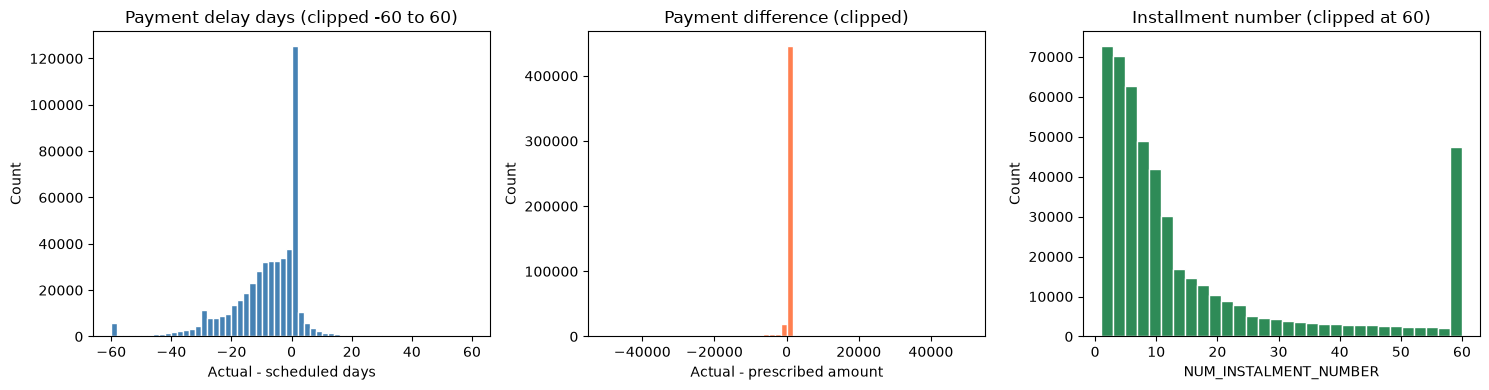

In [8]:
plot_df = installments.copy()
plot_df["payment_delay_days"] = plot_df["DAYS_ENTRY_PAYMENT"] - plot_df["DAYS_INSTALMENT"]
plot_df["payment_diff"] = plot_df["AMT_PAYMENT"] - plot_df["AMT_INSTALMENT"]

# Sample for plotting speed while keeping shape of distributions
plot_sample = plot_df.sample(n=min(500_000, len(plot_df)), random_state=42)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(
    plot_sample["payment_delay_days"].dropna().clip(-60, 60),
    bins=60,
    color="steelblue",
    edgecolor="white",
)
axes[0].set_title("Payment delay days (clipped -60 to 60)")
axes[0].set_xlabel("Actual - scheduled days")
axes[0].set_ylabel("Count")

axes[1].hist(
    plot_sample["payment_diff"].dropna().clip(-50000, 50000),
    bins=60,
    color="coral",
    edgecolor="white",
)
axes[1].set_title("Payment difference (clipped)")
axes[1].set_xlabel("Actual - prescribed amount")
axes[1].set_ylabel("Count")

axes[2].hist(
    plot_sample["NUM_INSTALMENT_NUMBER"].clip(upper=60),
    bins=30,
    color="seagreen",
    edgecolor="white",
)
axes[2].set_title("Installment number (clipped at 60)")
axes[2].set_xlabel("NUM_INSTALMENT_NUMBER")
axes[2].set_ylabel("Count")

plt.tight_layout()
plt.show()


## 8. FE / join / leakage notes

Preview client-level aggregates and document join paths. Payment behavior is historical relative to the current application, but still needs careful aggregation because of partial-payment rows.


In [9]:
installments_fe = installments.copy()
installments_fe["payment_delay_days"] = (
    installments_fe["DAYS_ENTRY_PAYMENT"] - installments_fe["DAYS_INSTALMENT"]
)
installments_fe["payment_diff"] = (
    installments_fe["AMT_PAYMENT"] - installments_fe["AMT_INSTALMENT"]
)
installments_fe["is_late"] = installments_fe["payment_delay_days"] > 0
installments_fe["is_underpay"] = installments_fe["payment_diff"] < 0

# Aggregate payments within previous-application + installment number first
instalment_group = (
    installments_fe.groupby(["SK_ID_CURR", "SK_ID_PREV", "NUM_INSTALMENT_NUMBER"], as_index=False)
    .agg(
        scheduled_amount=("AMT_INSTALMENT", "max"),
        paid_amount=("AMT_PAYMENT", "sum"),
        n_payment_events=("AMT_PAYMENT", "size"),
        max_delay_days=("payment_delay_days", "max"),
    )
)
instalment_group["group_underpay"] = instalment_group["paid_amount"] < instalment_group["scheduled_amount"]

client_fe_preview = (
    instalment_group.groupby("SK_ID_CURR", as_index=False)
    .agg(
        installment_count=("NUM_INSTALMENT_NUMBER", "count"),
        previous_apps_with_installments=("SK_ID_PREV", "nunique"),
        mean_max_delay_days=("max_delay_days", "mean"),
        late_installment_rate=("max_delay_days", lambda s: (s > 0).mean()),
        underpay_installment_rate=("group_underpay", "mean"),
        mean_paid_amount=("paid_amount", "mean"),
    )
)

display(Markdown("**Example client-level installment aggregates after grouping partial payments**"))
display(client_fe_preview.head(5).style.hide(axis="index"))


**Example client-level installment aggregates after grouping partial payments**

SK_ID_CURR,installment_count,previous_apps_with_installments,mean_max_delay_days,late_installment_rate,underpay_installment_rate,mean_paid_amount
100001,7,2,-7.285714,0.142857,0.000000,5885.132143
100002,19,1,-20.421053,0.000000,0.000000,11559.247105
100003,25,3,-7.160000,0.000000,0.000000,64754.586000
100004,3,1,-7.666667,0.000000,0.000000,7096.155000
100005,9,1,-23.555556,0.111111,0.000000,6240.205000


**Join path for FE:** aggregate installment payment events to `SK_ID_PREV` (or to installment groups first), then to `SK_ID_CURR`. Use `SK_ID_PREV` to link with `previous_application`, POS/cash, and credit-card tables.

**Leakage caution:** day fields are relative to the current application date and describe historical previous-loan payments, which is appropriate. Missing payment rows look like unpaid events and can become indicators, not fill targets.

**Fairness / proxy note:** this table has no protected attributes. Payment behavior may still correlate with socioeconomic factors, so client-level delay/underpayment features should be available for later audit in `07_protected_attributes.ipynb`.


## Summary of findings

_Executed successfully on 2026-07-16._

- **Grain / keys:** `installments_payments` has 13,605,401 rows x 8 columns (~871 MB). `SK_ID_CURR` and `SK_ID_PREV` have no nulls, and there are no exact duplicate rows. The grain is a payment event: `SK_ID_PREV + NUM_INSTALMENT_NUMBER` is not unique because partial payments create multiple rows for the same scheduled installment.
- **Missingness:** No column exceeds 50% missing. Only `DAYS_ENTRY_PAYMENT` and `AMT_PAYMENT` are incomplete (~0.021%, 2,905 rows), and they are always missing together, consistent with unpaid/unrecorded payments.
- **Coverage:** Installment history covers ~94.8% of train clients and ~98.4% of test clients. Clients with installment history have a higher raw train default rate (~8.2%) than clients without it (~6.0%); descriptive only. About 91% of installment `SK_ID_PREV` values join to `previous_application`, while only ~57% of previous applications have installment rows.
- **Volume:** Clients with history have a median of 25 payment rows (mean ~40, max 372). Previous applications with installments have a median of 10 payment rows.
- **Timing:** Most payments are early or on time (~91.6%). Late payments are ~8.4% of rows; delays >30 days (~0.3%) and >90 days (~0.1%) are rare but useful after aggregation.
- **Amounts:** Exact payments dominate (~89%). Underpayment is more common (~9.5%) than overpayment (~1.3%), often because one installment is split across multiple payment events.
- **Versions:** `NUM_INSTALMENT_VERSION` is mostly `1` (~62%) or `0` (~30%; credit-card calendars per the dictionary). Some previous applications change version over time.
- **FE implications:** Aggregate payment events within `SK_ID_PREV + NUM_INSTALMENT_NUMBER` first (sum paid amount, max delay), then roll up to `SK_ID_PREV` and `SK_ID_CURR`. Useful features include late rate, underpay rate, mean/max delay, and installment counts. Keep a missing-payment indicator.
- **Leakage / fairness notes:** Day fields are application-relative historical payments, so timing leakage risk is low if used as history. This table has no protected attributes, but payment behavior may still correlate with socioeconomic factors and should be available for later audit.
